In [37]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/27/2022
# version ='1.0'

# Demo: Further Experiments on Solving a Small SDP by Barrier Method -- II (continue.)

In book-convex-2004, the barrier method was used to solve the following SDP problem:
\begin{equation}
\begin{array}{rl}
\text{minimize} & c^Tx \\
\text{subject to} & F(x)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G \preceq 0 \\
\end{array}
\end{equation}
where $x\in R^n$, and $F_i\in S^p, G\in S^p$. 

As discussed in \cite{book-convex-2004}, the phase-I feasibility problem for the above SDP problem is

\begin{equation}
\begin{array}{rl}
\text{minimize} & s \\
\text{subject to} & R(x,s)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G-sI \preceq 0 \\
\end{array}
\end{equation}
which is also a SDP problem with 
$$
\begin{array}{rcl}
\hat{c} & = & \left[\begin{array}{c}
\mathbf{0}_{n} \\
1 \\
\end{array} \right] \\
\hat{F} & = & R(x,s) \\
\hat{F}_i & = & F_i,i=1,2,...,n \\
\hat{F}_{n+1} & = & -\mathbf{I}_{p\times p} \\
\hat{G} & = G \\
\end{array}
$$

However, the above feasibility problem may not be bounded as $s\rightarrow -\infty$. A variation of the feasibility problem is
\begin{equation}
\begin{array}{rl}
\text{minimize} & s \\
\text{subject to} & R(x,s)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G-sI \preceq 0 \\
& s\geq s_{min} \\
& x_i^2 \leq M^2, i=1,2,...,n \\
\end{array}
\end{equation}

Accordingly, the logarithmic barrier function and its gradient and hessian are
\begin{equation}
\begin{array}{rcl}
\phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
\nabla_{feas}(x,s) & = & \nabla \phi_{1}(x,s) + \nabla \phi_{2}(x,s) + \nabla \phi_3(x,s) \\
\nabla^2_{feas}(x,s) & = & \nabla^2 \phi_{1}(x,s) + \nabla^2 \phi_{2}(x,s) + \nabla^2 \phi_3(x,s) \\
\end{array}
\end{equation}
where
\begin{equation}
\begin{array}{rcl}
\phi_1(x,s) & = & -\log det(-R(x,s)) \\
\phi_2(x,s) & = & -\log (s-s_{min}) \\
\phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-s_i^2) \\
\end{array}
\end{equation}

In solving the phase-I feasibility problem by barrier method (using $\mu=50$), the starting point is 
$$
(x_{feas,0}, s_{feas,0})=(\vec{0}, \hat{s})
$$

where $\hat{s}=max(eig(G))+1$. During solving the feasibility problem, once a $s<0$ is found, the feasibility problem will break.

In [38]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [39]:
def is_pos_def(x):
    """
    utility function, check whether matrix x is positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) > 0)


def is_neg_def(x):
    """
    utility function, check whether matrix x is negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) < 0)


def is_semi_pos_def(x):
    """
    utility function, check whether matrix x is semi-positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) >= 0)


def is_semi_neg_def(x):
    """
    utility function, check whether matrix x is semi-negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) <= 0)

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [40]:
def my_f_0(x, c, F, G):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, c, F, G):
    return True


def my_gradient_f_0(x, c, F, G):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return c


def my_hessian_f_0(x, c, F, G):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-\log det(-F(x))$

If overflow occurs in calculating $det(-F(x))$,
then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
until no overflow occurs.

It requires $F(x)\succ 0$.

The gradient of $\phi(x)$,
   
   \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}

The Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$

In [41]:
def my_phi(x, c, F, G):
    """
    $\phi(x)=-\log det(-F(x))$
    If overflow occurs in calculating $det(-F(x))$,
    then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
    until no overflow occurs.
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    # print('Debug: trace(-Fx)={}'.format(np.trace(-Fx)))

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi = -1 * np.log(np.linalg.det(-Fx))
        if phi < 0 and np.isinf(phi):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 1 / 2
            if np.isinf(phi):
                raise RuntimeError('phi = -inf')
            return phi
        elif phi > 0 and np.isinf(phi):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 2
            if np.isinf(phi):
                raise RuntimeError('phi = +inf')
            return phi
        else:
            return phi


def my_phi_feasible(x, c, F, G):
    """
    It requires $F(x)\succ 0 $
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    return is_semi_neg_def(Fx)


def my_gradient_phi(x, c, F, G):
    """
    gradient of $\phi(x)$
    \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    g = [np.trace(-1 * np.linalg.inv(Fx) @ F[i]) for i in range(n)]
    return np.reshape(np.array(g), (n, 1))


def my_hessian_phi(x, c, F, G):
    """
    Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            H[i][j] = np.trace(minus_inv_Fx @ F[j] @ minus_inv_Fx @ F[i])

    if not is_pos_def(H):
        raise RuntimeError('Hessian should be positive.')
    return H

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [42]:
def my_f(x, t, c, F, G):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_f_0(x, c, F, G) + my_phi(x, c, F, G)


def my_f_feasible(x, t, c, F, G):
    return my_f_0_feasible(x, c, F, G) and my_phi_feasible(x, c, F, G)


def my_gradient_f(x, t, c, F, G):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_gradient_f_0(x, c, F, G) + my_gradient_phi(x, c, F, G)


def my_hessian_f(x, t, c, F, G):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_hessian_f_0(x, c, F, G) + my_hessian_phi(x, c, F, G)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [43]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')


Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [44]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [45]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, c, F, G):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    x = x0
    args = (barrier_t, c, F, G)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_search_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]
    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        x_next = x + step * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        #print(r'Info: iteration={}, barrier_t={}, decrement={}, line search step ={}'.format(iteration, barrier_t,
        #                                                                                     decrement, step))
        line_search_steps.append(step)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_search_steps

The logarithmic barrier function and its gradient and hessian are
\begin{equation}
\begin{array}{rcl}
\phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
\nabla_{feas}(x,s) & = & \nabla \phi_{1}(x,s) + \nabla \phi_{2}(x,s) + \nabla \phi_3(x,s) \\
\nabla^2_{feas}(x,s) & = & \nabla^2 \phi_{1}(x,s) + \nabla^2 \phi_{2}(x,s) + \nabla^2 \phi_3(x,s) \\
\end{array}
\end{equation}
where
\begin{equation}
\begin{array}{rcl}
\phi_1(x,s) & = & -\log det(-R(x,s)) \\
\phi_2(x,s) & = & -\log (s-s_{min}) \\
\phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
\end{array}
\end{equation}

In [46]:
def my_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi_1 = -1 * np.log(np.linalg.det(-Fx_hat))

        if phi_1 < 0 and np.isinf(phi_1):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx_hat = scale * Fx_hat
                phi_1 = -1 * (np.log(np.linalg.det(-scaled_Fx_hat)) - n_hat * np.log(scale))
                if not np.isinf(phi_1):
                    print('phi_s={}, scale = {}'.format(phi_1, scale))
                    break
                scale *= 1 / 2
            if np.isinf(phi_1):
                raise RuntimeError('phi = -inf')
        elif phi_1 > 0 and np.isinf(phi_1):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx_hat = scale * Fx_hat
                phi_1 = -1 * (np.log(np.linalg.det(-scaled_Fx_hat)) - n_hat * np.log(scale))
                if not np.isinf(phi_1):
                    print('phi_s={}, scale = {}'.format(phi_1, scale))
                    break
                scale *= 2
            if np.isinf(phi_1):
                raise RuntimeError('phi = +inf')

        s = xs[-1]
        phi_2 = -1 * np.log(s - s_min)

        phi_3 = 0
        for i in range(n_hat - 1):
            phi_3 += -1 * np.log(x_bound ** 2 - xs[i] ** 2)

        return phi_1 + phi_2 + phi_3


def my_phi_feasible_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]
    s = xs[-1]
    return is_semi_neg_def(Fx_hat) and s > s_min and np.all(xs[0:-1] > -x_bound) and np.all(xs[0:-1] < x_bound)


def my_gradient_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The gradient of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \nabla_{feas}(x,s) & = & \nabla \phi_{1}(x,s) + \nabla \phi_{2}(x,s) + \nabla \phi_3(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-s_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]
    g1 = [np.trace(-1 * np.linalg.inv(Fx_hat) @ F_hat[i]) for i in range(n_hat)]

    s = xs[-1]
    g2 = np.zeros((n_hat, 1))
    g2[-1][0] = -1 / (s - s_min)

    g3 = np.zeros((n_hat, 1))
    for i in range(n_hat - 1):
        g3[i][0] = 2 * xs[i] / (x_bound ** 2 - xs[i] ** 2)

    return np.reshape(np.array(g1), (n_hat, 1)) + g2 + g3


def my_hessian_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The hessian of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \nabla^2_{feas}(x,s) & = & \nabla^2 \phi_{1}(x,s) + \nabla^2 \phi_{2}(x,s) + \nabla^2 \phi_3(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-s_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx_hat)
    H1 = np.zeros((n_hat, n_hat))
    for i in range(n_hat):
        for j in range(n_hat):
            H1[i][j] = np.trace(minus_inv_Fx @ F_hat[j] @ minus_inv_Fx @ F_hat[i])

    s = xs[-1]
    H2 = np.zeros((n_hat, n_hat))
    H2[n_hat - 1][n_hat - 1] = 1 / ((s - s_min) ** 2)

    H3 = np.zeros((n_hat, n_hat))
    for i in range(n_hat - 1):
        H3[i][i] = 2 / (x_bound ** 2 - xs[i] ** 2) + 4 * (xs[i] ** 2) / ((x_bound ** 2 - xs[i] ** 2) ** 2)

    if not is_pos_def(H1):
        raise RuntimeError('Hessian I should be positive.')
    if not is_pos_def(H1 + H2 + H3):
        raise RuntimeError('Hessian I+II+III should be positive.')
    return H1 + H2 + H3

In [47]:
def my_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_f_0(xs, c_hat, F_hat, G_hat) + my_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_f_phase_I_feasible(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return my_f_0_feasible(xs, c_hat, F_hat, G_hat) and my_phi_feasible_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_gradient_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_gradient_f_0(xs, c_hat, F_hat, G_hat) + my_gradient_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_hessian_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_hessian_f_0(xs, c_hat, F_hat, G_hat) + my_hessian_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$, in the phase-I feasibility problem

In [48]:
def my_newton_step_decrement_phase_I(xs, args):
    gradient = my_gradient_f_phase_I(xs, *args)
    hessian = my_hessian_f_phase_I(xs, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [49]:
def backtracking_line_search_phase_I(f, df, xs, delta_x, alpha, beta, args):
    step = 1
    while (not my_f_phase_I_feasible(xs + delta_x * step, *args)) \
            or f(xs + delta_x * step, *args) > f(xs, *args) + alpha * step * ((df(xs, *args).T @ delta_x).item()):
        step = beta * step
    return step

The centering step, in solving the phase-I feasibility problem, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [50]:
def centering_step_phase_I(xs0, epsilon, alpha, beta, barrier_t, c_hat, F_hat, G_hat, s_min, x_bound,
                           max_iteration=100):
    xs = xs0
    args = (barrier_t, c_hat, F_hat, G_hat, s_min, x_bound)
    xs_nt, decrement = my_newton_step_decrement_phase_I(xs, args)

    line_search_steps = []
    fx = [my_f_phase_I(xs, *args)]
    decrements = [decrement]

    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search_phase_I(my_f_phase_I, my_gradient_f_phase_I, xs, xs_nt, alpha, beta, args)
        xs_next = xs + step * xs_nt
        xs = xs_next

        xs_nt, decrement = my_newton_step_decrement_phase_I(xs, args)
        line_search_steps.append(step)
        fx.append(my_f_phase_I(xs, *args))
        decrements.append(decrement)

        iteration = iteration + 1
        if iteration > max_iteration:
            break

    n_iter = iteration
    xst = xs
    return xst, n_iter, fx, decrements, line_search_steps

To get a strict feasible start point by solving the phase-I feasibility  problem

Refer to the FlexibleLecture Note for detail

In [51]:
def get_strict_feasible_start_point(c, F, G):
    """
    To get a strict feasible start point by solving the phase-I feasibility  problem
    Refer to the FlexibleLecture Note for detail
    :param c:
    :param F:
    :param G:
    :return:
    """
    ax0 = plt.subplot(6, 1, 1)
    ax0_twin = ax0.twinx()

    ax1 = plt.subplot(6, 1, 2)
    color = 'black'

    n_hat, p, _ = F.shape
    c_hat = np.zeros((n_hat + 1, 1))
    c_hat[n_hat][0] = 1

    F_hat = np.zeros((n_hat + 1, p, p))
    np.copyto(F_hat[0:n_hat], F)

    F_hat[n_hat] = -np.eye(p)
    G_hat = G.copy()

    x0 = np.zeros((n_hat, 1))
    Tmp = G_hat.copy()
    for i in range(n_hat):
        Tmp += x0[i] * F_hat[i]
    eig_vals = np.linalg.eigvals(Tmp)
    s = np.max(eig_vals) + 1

    xs0 = np.block([[x0], [np.reshape(np.array([s]), (1, 1))]])

    Tmp = G_hat.copy()
    for i in range(n_hat + 1):
        Tmp += xs0[i] * F_hat[i]
    if not is_neg_def(Tmp):
        raise RuntimeError('xs0 should be negative definite.')

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-3
    mu = 50

    t0 = 1
    t = t0

    cumulative_iteration = 0
    dual_gaps = []
    decrements = []
    fx_es = []
    iteration_index_vs_decrement = []

    # To ensure that the initial point is on the central path with t_0 = 1
    s_min = -100
    x_bound = 100
    args = (t, c_hat, F_hat, G_hat, s_min, x_bound)
    xst, n_iter, fx, decrement, tx = centering_step_phase_I(xs0, epsilon, alpha, beta, *args)
    xs0 = xst

    dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
    decrements = decrements + decrement
    fx_es = fx_es + (np.array(fx) / t).tolist()
    iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(cumulative_iteration,
                                                                                    cumulative_iteration + n_iter)]
    cumulative_iteration = cumulative_iteration + n_iter - 1
    t = mu * t
    n_hat = len(xst)
    feasible = False
    while True:
        args = (t, c_hat, F_hat, G_hat, s_min, x_bound)
        xst, n_iter, fx, decrement, tx = centering_step_phase_I(xs0, epsilon, alpha, beta, *args)
        xs0 = xst

        dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
        decrements = decrements + decrement
        fx_es = fx_es + (np.array(fx) / t).tolist()
        iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(cumulative_iteration,
                                                                                        cumulative_iteration + n_iter)]
        cumulative_iteration = cumulative_iteration + n_iter - 1
        if my_f_0(xs0, c_hat, F_hat, G_hat) < 0:
            feasible = True
            break

        if p / t < duality_gap_epsilon:
            break
        else:
            t = mu * t

    dual_gaps = dual_gaps + [p / t]
    fx_list = np.squeeze(np.array(fx_es)).tolist() + [my_f(x0, t, c, F, G) / t]

    ax0.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], dual_gaps, color=color,
                 linestyle='solid',
                 label=r'$\mu$={}, phase_I feasibility problem'.format(mu))
    ax0_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
    ax0.xaxis.set_minor_locator(MultipleLocator(1))
    ax0.xaxis.set_major_locator(MultipleLocator(5))
    ax0.xaxis.grid(True, which='both')
    ax0.set_ylabel('duality_gap')
    ax0_twin.set_ylabel(r'$\lambda^2$')
    ax0.legend(loc='lower left')

    ax1.plot(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], (np.array(fx_list)), marker='x',
             color=color, linestyle='solid',
             label=r'$\mu$={}, phase_I feasibility problem'.format(mu))
    ax1.xaxis.set_minor_locator(MultipleLocator(1))
    ax1.xaxis.set_major_locator(MultipleLocator(5))
    ax1.xaxis.grid(True, which='both')
    ax1.set_ylabel(r'$f_0(x)+\phi(x)/t$')
    ax1.legend(loc='upper left')

    if feasible:
        return xs0[0:n_hat - 1]
    else:
        return None

In [52]:
def get_c_F_G_xp_Z(n, p, p_asterisk):
    """
    Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$
    Refer to FlexibleLecture Note for details
    :param n:
    :param p:
    :param p_asterisk:
    :return:
    """
    if not p_asterisk > 0:
        raise RuntimeError('Only fp > 0 is supported yet.')

    dial = 0
    while True:
        x_asterisk = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        dx = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        assert (not np.allclose(dx[n - 1][0], 0))
        F = np.zeros((n, p, p))
        Tmp = np.random.rand(p, p)
        R = -1 * (Tmp @ Tmp.T)  # -R is SDP

        for i in range(n - 1):
            Tmp = np.random.normal(loc=0, scale=1.0, size=(p, p))
            F[i] = (Tmp + Tmp.T) / 2  # $F_i$ is symmetric

        Tmp = np.zeros((p, p))
        for i in range(n - 1):
            Tmp += dx[i][0] * F[i]

        F[n - 1] = (R - Tmp) / dx[n - 1][0]

        Tmp = np.zeros((p, p))
        for i in range(n):
            Tmp += dx[i][0] * F[i]
        if not is_neg_def(Tmp):
            raise RuntimeError('F(dx)-G should be negative definite!')

        G = np.zeros((p, p))
        for i in range(n):
            G += -x_asterisk[i][0] * F[i]

        Tmp = np.random.rand(p, p)
        Z_tmp = Tmp @ Tmp.T
        scale = p_asterisk / np.trace(Z_tmp @ G)
        if scale > 0:
            Z = Z_tmp * scale
            #print('Info: model parameters are successfully constructed.')
            break
        else:
            dial += 1
            #print('Info: The {}-th dial to generate Z failed, continue to the next dial'.format(dial))
            continue

    if not np.allclose(np.trace(Z @ G), p_asterisk):
        raise RuntimeError('it is requiring the optimal value is fp.')

    Tmp = G.copy()
    for i in range(n):
        Tmp += x_asterisk[i][0] * F[i]

    if not np.allclose(Tmp, np.zeros((p, p))):
        raise RuntimeError('it should satisfy the optimal condition, F(xp)=0')

    x0 = x_asterisk + dx

    Tmp = G.copy()
    for i in range(n):
        Tmp += x0[i][0] * F[i]
    if not is_neg_def(Tmp):
        raise RuntimeError('it should have F(x0)<0')

    c = np.zeros((n, 1))
    for i in range(n):
        c[i][0] = -np.trace(Z @ F[i])

    return c, F, G, Z, x_asterisk, x0

In [53]:
def plot_figure_feasibility_start_convergence(n, p, fp, seed, mu_s):
    """
    plot figure about the progress of barrier method for a small SDP, showing duality
    gap (including the phase-I feasibility problem), Newton decrement, Newton step length,
    $f_0-f_p (f_p=p^*)$  versus cumulative number of Newton steps
    :param n:
    :param p:
    :param fp:
    :param seed:
    :param mu_s:
    :return:
    """
    plt.figure(figsize=(12, 10))
    ax2 = plt.subplot(6, 1, 3)
    ax2_twin = ax2.twinx()

    ax3 = plt.subplot(6, 1, 4)
    ax4 = plt.subplot(6, 1, 5)
    ax5 = plt.subplot(6, 1, 6)

    colors = ['black', 'purple', 'orange', 'magenta']
    markers = ['o', 's', 'v', '<']

    np.random.seed(seed)
    c, F, G, Z, xp, _ = get_c_F_G_xp_Z(n, p, fp)

    Fx = G.copy()
    for i in range(n):
        Fx += xp[i][0] * F[i]
    if not is_semi_neg_def(Fx):
        if not np.allclose(np.linalg.eigvals(Fx), np.zeros((p,))):
            raise RuntimeError('it should Fx <= 0')
    if not np.allclose(np.trace(Z @ Fx), 0):
        raise RuntimeError('tr(Z @ Fx)=0')
    if not is_semi_pos_def(Z):
        raise RuntimeError('it should be Z >= 0')
    g = np.reshape(np.array([np.trace(Z @ F[i]) for i in range(n)]), (n, 1))
    if not np.allclose(-c, g):
        raise RuntimeError('it should c+g=0')

    # use phase I method to get a feasible start point x0
    x0 = get_strict_feasible_start_point(c, F, G)

    print('start solving small SDP...')
    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4

    for mu_i, mu in enumerate(mu_s):
        color = colors[mu_i]
        marker = markers[mu_i]

        t0 = 1
        t = t0

        cumulative_iteration = 0
        dual_gaps = []
        decrements = []
        fx_es = []
        iteration_index_versus_decrement = []

        search_steps = []
        f0 = []

        # To ensure that the initial point is on the central path with t_0 = 1
        args = (t, c, F, G)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

        f0 = f0 + [my_f_0(x0, c, F, G)] * len(decrement)
        search_steps = search_steps + tx
        dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
        decrements = decrements + decrement
        fx_es = fx_es + (np.array(fx) / t).tolist()
        iteration_index_versus_decrement = iteration_index_versus_decrement + [i for i in range(cumulative_iteration, cumulative_iteration + n_iter)]
        cumulative_iteration = cumulative_iteration + n_iter - 1

        x0 = xt
        t = mu * t
        while True:
            args = (t, c, F, G)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

            f0 = f0 + [my_f_0(x0, c, F, G)] * len(decrement)
            search_steps = search_steps + tx
            dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
            decrements = decrements + decrement
            fx_es = fx_es + (np.array(fx) / t).tolist()
            iteration_index_versus_decrement = iteration_index_versus_decrement + [i for i in range(cumulative_iteration, cumulative_iteration + n_iter)]
            cumulative_iteration = cumulative_iteration + n_iter - 1

            x0 = xt
            if p / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

        f0 = f0 + [my_f_0(x0, c, F, G)]
        dual_gaps = dual_gaps + [p / t]

        ax2.semilogy(iteration_index_versus_decrement + [max(iteration_index_versus_decrement)], dual_gaps, color=color, linestyle='solid',
                     label=r'$\mu$={}'.format(mu))
        ax2_twin.semilogy(iteration_index_versus_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax2.xaxis.set_minor_locator(MultipleLocator(1))
        ax2.xaxis.set_major_locator(MultipleLocator(5))
        ax2.xaxis.grid(True, which='both')
        ax2.set_ylabel('duality_gap')
        ax2_twin.set_ylabel(r'$\lambda^2$')

        ax3.plot(range(1, len(search_steps) + 1), search_steps, marker=marker, fillstyle='none', color=color, linestyle='solid',
                 label=r'$\mu$={}'.format(mu))
        ax3.xaxis.set_minor_locator(MultipleLocator(1))
        ax3.xaxis.set_major_locator(MultipleLocator(5))
        ax3.xaxis.grid(True, which='both')
        ax3.set_ylabel('newton step length: t')

        ax4.semilogy(iteration_index_versus_decrement + [max(iteration_index_versus_decrement)], np.squeeze(np.abs(np.array(f0) - fp)),
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}'.format(mu, fp))
        ax4.xaxis.set_minor_locator(MultipleLocator(1))
        ax4.xaxis.set_major_locator(MultipleLocator(5))
        ax4.xaxis.grid(True, which='both')
        ax4.set_ylabel('f0-fp')

        ax5.semilogy(iteration_index_versus_decrement, abs(np.array(fx_es)) + 1e-14,
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}'.format(mu, fp))
        ax5.xaxis.set_minor_locator(MultipleLocator(1))
        ax5.xaxis.set_major_locator(MultipleLocator(5))
        ax5.xaxis.grid(True, which='both')
        ax5.set_xlabel('iteration')
        ax5.set_ylabel(r'$abs(f_0(x)+\phi(x)/t)$')

    ax2.legend()
    ax3.legend()
    ax4.legend()
    ax5.legend()
    plt.show()

start solving small SDP...


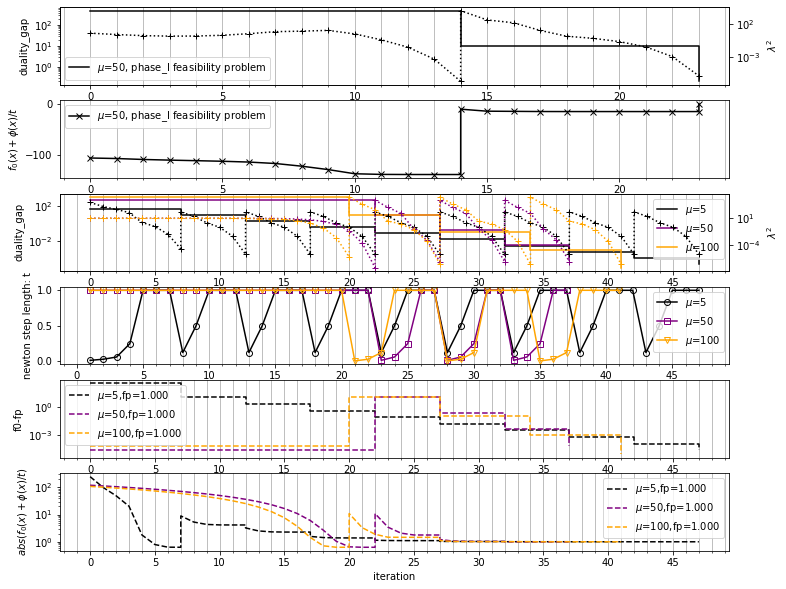

In [54]:
if __name__ == "__main__":
    plot_figure_feasibility_start_convergence(n=10, p=10, fp=1, seed=2, mu_s=[5, 50, 100])